In [46]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from numpy.polynomial.legendre import legvander

In [47]:
SEED = 42                           # SEED wird dafür gebraucht, dass sich nicht bei jedem Lauf die Anfangsbedingungen, die Trainings-, Validierungsdaten und die Anfänglichen Gewichte des Autoencoders verändern
                                    # Damit wird ein Autoencoder mit verschiedenen Aktivierungsfunktionen vergleichbar
np.random.seed(SEED)
torch.manual_seed(SEED)             # PyTorch SEED. Modellgewichte beginnen bei erneutem Durchlauf mit der gleichen zufälligen Initialisierung

rng = np.random.default_rng(SEED)

# Anzahl der Trajektorien
N_TRAIN_TRAJECTORIES = 100
N_VAL_TRAJECTORIES = 20


BATCH_SIZE = 1024                   # Pro optimierungsschritt werden höchsten 1024 Übergänge verarbeitet
EPOCHS = 700                        # Anzahl der Epochen, die trainiert werden. 1 Epoche = Modell hat alle Trainingsdateien gesehen
LEARNING_RATE = 3e-4                # Schrittweite des Adam Optimierers
PRINT_FREQUENCY = 10

NOISE_STRENGTH = 0.05

Definition des Lorenzsystems

In [48]:
def lorenz(state, t, sigma=10., rho=28., beta=8/3):

    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]

Räumliche Basis

In [49]:
t = np.arange(0.0, 5.0, 0.02)       # Erzeugen eines Zeitvektors. t = 0.0 bis t = 5.0 Schrittweite = 0.02. Ergibt 250 Zeitpunkte. t + 1 bedeutet nächte Arrayindex
grid = np.linspace(-1, 1, 128)      # Erzeugt 128 gleichmäßig verteilte Punkte auf dem Intervall [-1, 1]
U = legvander(grid, 5)              # Erzeugt Vandermonde-Matrix für Legendre-Polynome. Für jeden Punkt aus grid werden die ersten 6 Legendre-Polynome ausgewertet.

Erstellen des künstlichen 128 dimensionalen Datensatz

In [50]:
def create_lorenz_dataset(number_of_trajectories):
    ic_means = np.array([0.0, 0.0, 25.0])                                                                       # Mittelpunkte der Verteilung der Anfangszustände
    ic_widths = 2.0 * np.array([36.0, 48.0, 41.0])                                                              # Intervallbreiten
    initial_conditions = (ic_widths * (np.random.rand(number_of_trajectories, 3) - 0.5)) + ic_means             # Erstellen der zufälligen Anfangszustände

    Z_raw = np.stack([odeint(lorenz, z0, t) for z0 in initial_conditions])                                      # Für jede Anfangsbedingung z0 wird das Lorenz System über die 250 Zeitpunkte integriert.

    Z_scaled = Z_raw / 40.0                                                                                     # Skalierung

    Z_scaled = Z_scaled.astype(np.float32)                                                                      # Wandelt in Gleitkommazahl um (Für PyTorch)

    modes = np.concatenate([                                                                                    # Erstellen der Gleichung aus dem Paper: z1(t), z2(t), z3(t), z1(t)^3, z2(t)^3, z3(t)^3
        Z_scaled,
        Z_scaled**3
    ], axis=2)

    X = modes @ U.T                                                                                             # modes wird mit transponierter Legendre-Matrix multipliziert

    return Z_raw, Z_scaled, X.astype(np.float32)

Trainings, Validierrungsdaten erzeugen

In [51]:
# Daten werden nach Trajektorien getrennt
Z_train_raw, Z_train, X_train = create_lorenz_dataset(N_TRAIN_TRAJECTORIES)
Z_val_raw, Z_val, X_val = create_lorenz_dataset(N_VAL_TRAJECTORIES)


Erzeugung der t- und t + 1-Paare

In [52]:
# X(t)
X_train_t = X_train[:, :-1, :].reshape(-1, 128)
X_val_t = X_val[:, :-1, :].reshape(-1, 128)

# X(t+1)
X_train_tp1 = X_train[:, 1:, :].reshape(-1, 128)
X_val_tp1 = X_val[:, 1:, :].reshape(-1, 128)

 # Erstellt PyTorch tensor und ascontiguousarray sorgt dafür, dass die Daten zusammenhängend im Speicher liegen
X_train_t_tensor = torch.from_numpy(np.ascontiguousarray(X_train_t))
X_train_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_train_tp1))
X_val_t_tensor = torch.from_numpy(np.ascontiguousarray(X_val_t))
X_val_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_val_tp1))

Daten für Training mit PyTorch vorbereiten

In [53]:
train_dataset = TensorDataset(
    X_train_t_tensor,
    X_train_tp1_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,                                  # BATCH SIZE verarbeitet höchstens BATCH_SIZE Übergänge gleichzeitig. Ein Übergang ist: X(t) -> X(t+1)
    shuffle=True,
    drop_last=False
)

Erstellen des Autoencoders

In [54]:
class PredictiveAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(128, 64),
            nn.SiLU(),

            nn.Linear(64, 32),
            nn.SiLU(),

            nn.Linear(32, 16),
            nn.SiLU(),

            nn.Linear(16, 3)
        )

        # Soll zeitliche Bewegung im dreidimensionalen latenten Raum lernen
        # Bekommt aktuellen Latenten Zustand und berechnet wie sich dieser bis zum nächsten Zeitpunkt verändern soll
        self.latent_dynamics = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),
            nn.Linear(16, 3)
        )

        self.decoder = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),

            nn.Linear(16, 32),
            nn.SiLU(),

            nn.Linear(32, 64),
            nn.SiLU(),

            nn.Linear(64, 128)
        )
    # Beschreibt den vollständigen Vorwärtsdurchlauf des Modells während des Trainings und der Validierung
    def forward(self, x_t, x_tp1):                                          # x_t = aktueller Zustand, x_tp1 = echter nächste Zustand

        z_t = self.encoder(x_t)                                             # Komprimiert 128d Zustand auf drei latente Werte. X(t) durch encoder

        z_tp1 = self.encoder(x_tp1)                                         # Tatsächlich vorhandener nächster Zustand ebenfalls auf drei Dimensionen komprimiert. Echtes X(t+1) durch Encoder

        x_t_hat = self.decoder(z_t)                                         # Rekonstruktion von X(t). z(t) wird durch den decoder geschickt

        delta_z = self.latent_dynamics(z_t)                                 # Berechnet die vorhergesagte Veränderung im Latentraum. Dynamiknetz sieht nicht den tatsächlichen Folgezustand x_tp1, sondern es muss die Änderung
                                                                            # ausschließlich aus z_t vorhersagen

        z_tp1_hat = z_t + delta_z                                           # Eigentliche ein schritt Vorhersage Z^hat(t+1) ) = z(t) + F(z(t)) Residualform sinnvoll, da zwei aufeinanderfolgende Zustände bei delta_t = 0,02
                                                                            # meist relativ nah zusammenliegen

        x_tp1_hat = self.decoder(z_tp1_hat)                                 # Decodiert vorhergesagten latenten Zustand in 128d zurück

        return x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat                         # x_t_hat = Rekonstruktion von X(t), z_tp1 = latente Dartsellung des echten X(t+1), z_tp1_hat = vorhergesagter latenter Zustand,
                                                                            # x_tp1_hat = vorhergesagter nächster 128D-Zustand

Trainieren des Autoencoders

In [55]:
model = PredictiveAutoencoder()                                             # Erstellen des Models

criterion = nn.MSELoss()                                                    # Mean Squared Error Fehlerfunktion. Berechnet durchschnittliche quadratische Abweichung zwischen Vorhersage und Ziel. Durch quadreieren werden
                                                                            # größere Abweichungen stärker bestraft

optimizer = torch.optim.Adam(                                               # Adam optimierungsalgorithmus
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)   # Dynamische Learningrate (cosinusförmig)

train_loss_history = []
val_loss_history = []

val_reconstruction_history = []
val_latent_history = []
val_prediction_history = []

for epoch in range(EPOCHS):

    model.train()                                                           # Trainingsmodus
    total_train_loss = 0.0
    total_train_samples = 0

    for x_t, x_tp1 in train_loader:                                         # Lädt einen Batch zusammengehöriger X(t)- und X(t+1)-Zustände
        optimizer.zero_grad()                                               # Lösche Gradienten aus dem vorherigen Batch. Sonst würde die Gradienten immer addiert werden Gradient beschreibt wie sich der Loss verändert.
                                                                            # positiver Gradient: Gewicht eher verkleinern,
                                                                            # negativer Gradient: Gewicht eher vergrößern,
                                                                            # großer Betrag: stärkere Änderung,
                                                                            # kleiner Betrag: kleinere Änderung.
        if NOISE_STRENGTH > 0:
            noise = NOISE_STRENGTH * torch.randn_like(x_t)
            x_t_noisy = x_t + noise
        else:
            x_t_noisy = x_t

        x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat = model(x_t_noisy, x_tp1)      # Vorwärtsdurchlauf (Ruft funktion forward auf).




        reconstruction_loss = criterion(x_t_hat, x_t)                       # Berechnet den Rekonstruktionsfehler. Sorgt dafür, dass der dreidimensionale Latentraum genügend Informationen zur Rekonstruktion erhält.
                                                                            # Rekonstruktion wird mit der ursprünglichen Eingabe verglichen. Trainiert hauptsächlich Encoder + Decoder

        latent_loss = criterion(z_tp1_hat, z_tp1)                           # Berechnet den Latentenfehler. Dadurch soll die Vorhersage mit dem Encoder-Ergebnis des echten nächsten Zustand übereinstimmen. z_tp1 ist nicht mit
                                                                            # .detach() vom Gradientenfluss getrennt. Daher beeinflusst dieser Fehler das Dynamiknetz und den Encoder -> gemeinsames Training
                                                                            #  Das vorhergesagtes z_hat(t+1) und X(t+1) werden verglichen

        prediction_loss = criterion(x_tp1_hat, x_tp1)                       # Vorhersagefehler. Wichtigster Fehler für die Ein-Schritt Vorhersage.
                                                                            # Vorhergesagte Zukunft wird mit der tatsächlichen Zukunft verglichen

        loss = (reconstruction_loss + 0.1 * latent_loss + prediction_loss)  # Gesamtfehler.
                                                                            # Ein zu stark gewichteter Latent loss könnte die Optimierung dominieren und Rekonstruktion der physischen Vorhersage verschlechtern.

        loss.backward()                                                     # Berechnet mit Backpropagation die Gradienten aller Modellparameter
        optimizer.step()                                                    # Aktualisiert Encoder, Dynamiknetz und Decoder

        batch_size = x_t.shape[0]                                           # Ermittelt die tatsächliche Größe des aktuellen Batches, da das letzte Batch meistens eine andere Größe hat

        total_train_loss += loss.item() * batch_size                        # Multipliziert den mittleren Batchfehler mit der Zahl der Beispiele. Dadurch kann später ein korrekt gewichteter Mittelwert berechnet werden.
                                                                            # Wichtig da auch die größe des letzten Batches miteinbezogen wird
        total_train_samples += batch_size                                   # Zählt die verarbeiteten Beispiele.

    train_loss = total_train_loss / total_train_samples                     # Mittlerer Gesamtfehler über alle Trainingsübergänge der gesamten Epoche
    train_loss_history.append(train_loss)                                   # Speichert wert für späteren Plot.

    model.eval()                                                            # Modell wird in Auswertungsmodus gesetzt

    with torch.inference_mode():                                                                    # Deaktiviert Gradientenberechnung -> Validierung wird schneller
        x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat = model(X_val_t_tensor, X_val_tp1_tensor)              # Verarbeitet Validierungsdatensatz auf einmal
        val_reconstruction_loss = criterion(x_t_hat, X_val_t_tensor)                                # Misst Rekonstruktion von X(t)
        val_latent_loss = criterion(z_tp1_hat, z_tp1)                                               # Misst Vorhersage von z(t+1)
        val_prediction_loss = criterion(x_tp1_hat, X_val_tp1_tensor)                                # Misst die Vorhersage von X(t+1)
        val_loss = (val_reconstruction_loss + 0.1 * val_latent_loss + val_prediction_loss)          # Gesamtfehler der Validierung. Berechnung ist identisch zum Trainingsfehler

    # Werte speichern für Graphen
    val_loss_history.append(val_loss.item())                                                        # Durch .append wird der fehler immer hinten an die Liste angefügt. Dies ermöglicht das plotten
    val_reconstruction_history.append(val_reconstruction_loss.item())
    val_latent_history.append(val_latent_loss.item())
    val_prediction_history.append(val_prediction_loss.item())

    scheduler.step()                                                            # Learningrate wird angepasst

    if epoch % PRINT_FREQUENCY == 0 or epoch == EPOCHS - 1:
        print(
            f"Epoch {epoch:4d} | "
            f"Training: {train_loss:.6e} | "
            f"Validierung: {val_loss.item():.6e} | "
            f"Rekonstruktion: "
            f"{val_reconstruction_loss.item():.6e} | "
            f"Latent t+1: "
            f"{val_latent_loss.item():.6e} | "
            f"Vorhersage X(t+1): "
            f"{val_prediction_loss.item():.6e}"
        )

22070
Epoch    0 | Training: 3.942119e-01 | Validierung: 3.598018e-01 | Rekonstruktion: 1.794118e-01 | Latent t+1: 3.162015e-02 | Vorhersage X(t+1): 1.772280e-01
Epoch   10 | Training: 8.403425e-02 | Validierung: 7.215322e-02 | Rekonstruktion: 3.557631e-02 | Latent t+1: 2.255026e-02 | Vorhersage X(t+1): 3.432189e-02
Epoch   20 | Training: 2.116740e-02 | Validierung: 2.026289e-02 | Rekonstruktion: 8.958709e-03 | Latent t+1: 2.294647e-02 | Vorhersage X(t+1): 9.009531e-03
Epoch   30 | Training: 1.610874e-02 | Validierung: 1.584949e-02 | Rekonstruktion: 7.465843e-03 | Latent t+1: 1.198141e-02 | Vorhersage X(t+1): 7.185505e-03
Epoch   40 | Training: 1.374453e-02 | Validierung: 1.345470e-02 | Rekonstruktion: 6.540711e-03 | Latent t+1: 7.636603e-03 | Vorhersage X(t+1): 6.150326e-03
Epoch   50 | Training: 1.205932e-02 | Validierung: 1.183969e-02 | Rekonstruktion: 5.824625e-03 | Latent t+1: 6.367509e-03 | Vorhersage X(t+1): 5.378315e-03
Epoch   60 | Training: 1.039263e-02 | Validierung: 1.01177

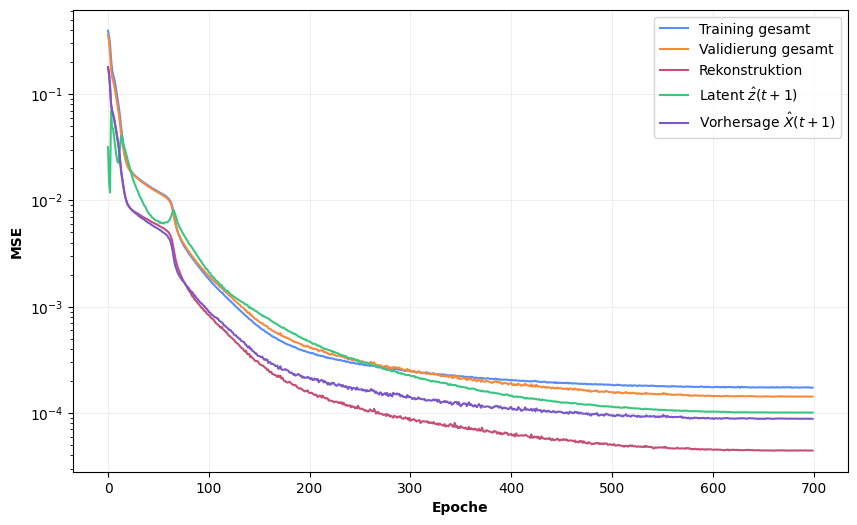

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(train_loss_history, label="Training gesamt")

plt.plot(val_loss_history, label="Validierung gesamt")

plt.plot(val_reconstruction_history, label="Rekonstruktion")

plt.plot(val_latent_history, label=r"Latent $\hat{z}(t+1)$")

plt.plot(val_prediction_history, label=r"Vorhersage $\hat{X}(t+1)$")

plt.yscale("log")
plt.xlabel("Epoche", fontweight='bold')
plt.ylabel("MSE", fontweight='bold')


plt.legend()
plt.grid(alpha=0.3)

plt.savefig("Gemeinsames_Training_Mit_Rauschen.pdf", dpi=200)

plt.show()

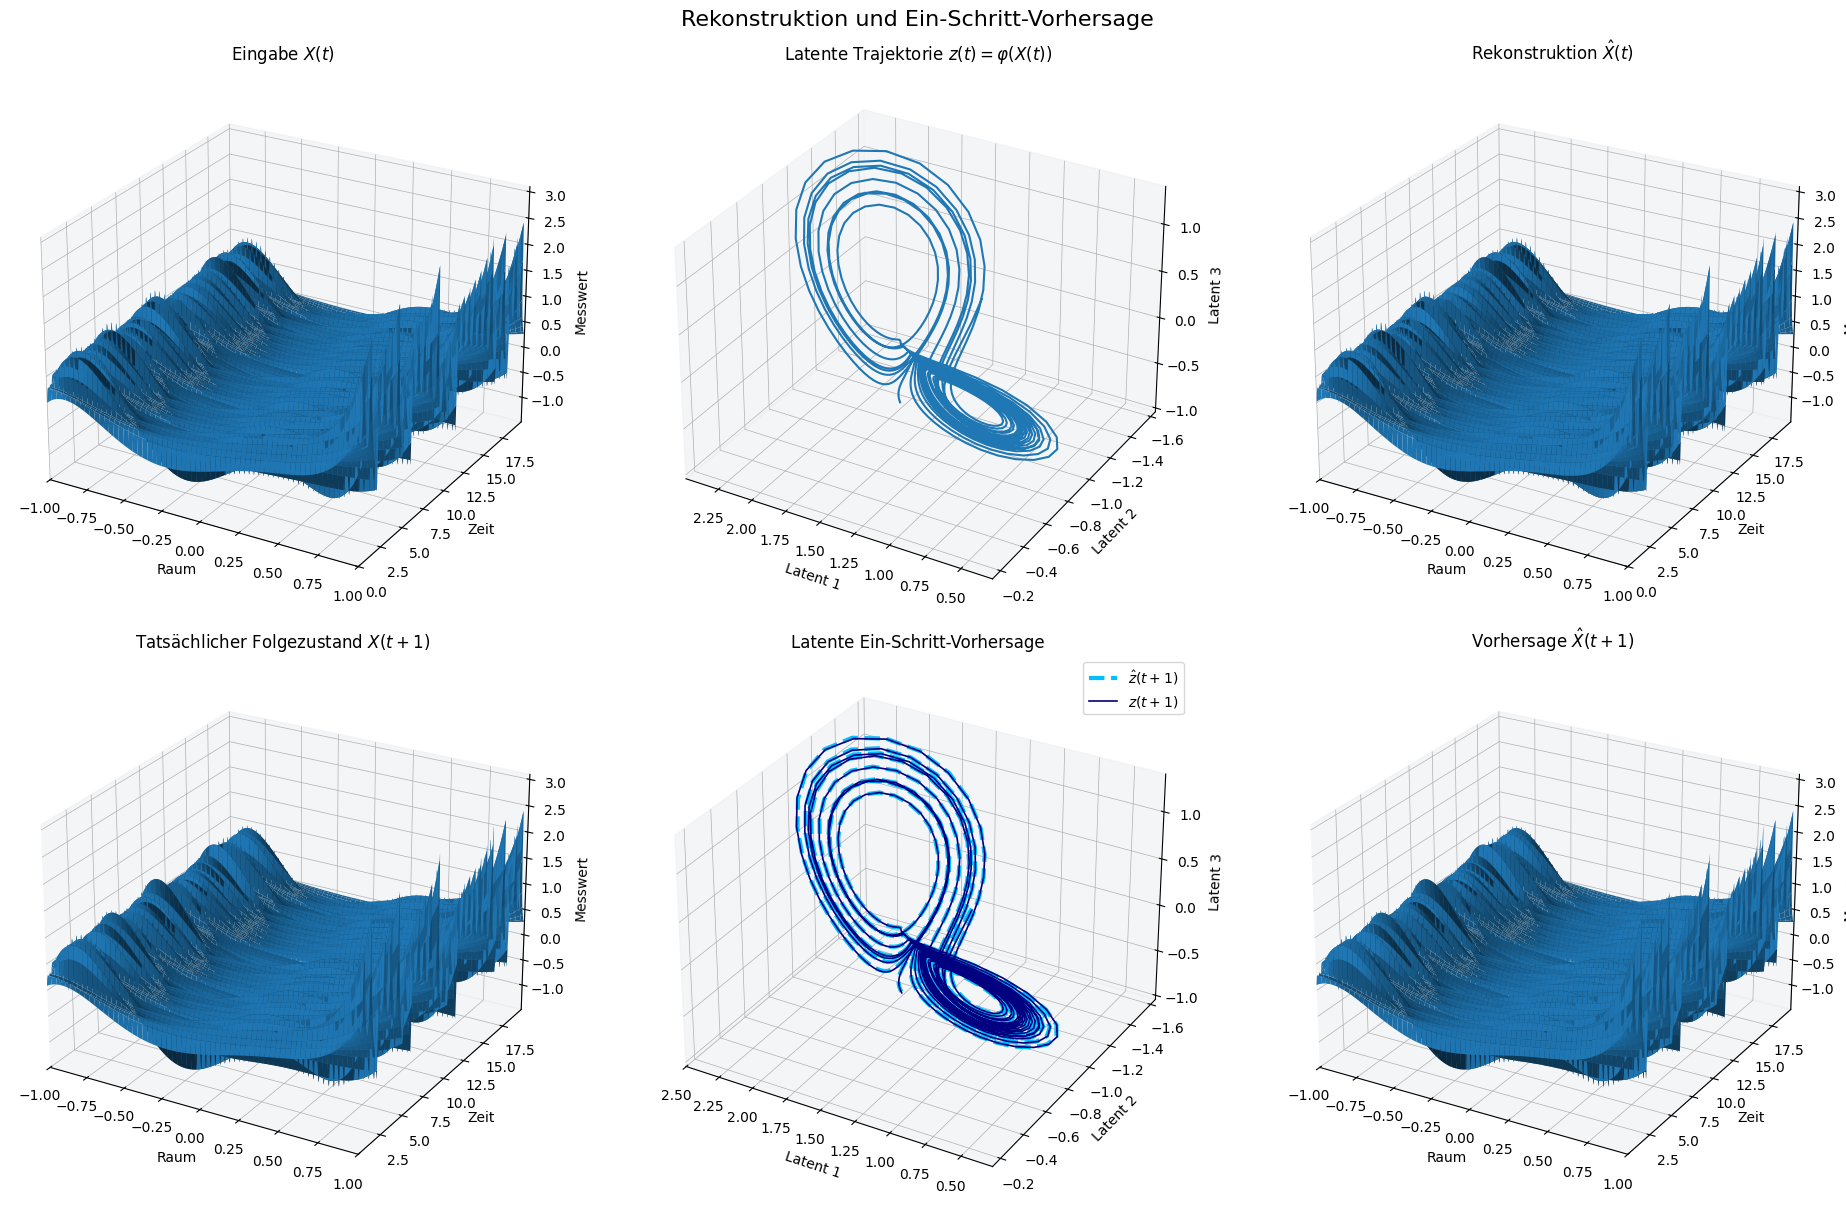

In [57]:
t_plot = np.arange(0.0, 20.0, 0.02)
z0_plot = np.array([-8.0, 7.0, 27.0])

# Das Modell wurde mit einer Schrittweite von 0.02 trainiert

# Lorenz-System simulieren und wie beim Training simulieren
Z_plot_raw = odeint(lorenz, z0_plot, t_plot)
Z_plot = (Z_plot_raw / 40.0).astype(np.float32)

# Die gleiche 128D-Abbildung wie beim Training
modes_plot = np.concatenate(
    [Z_plot, Z_plot**3],
    axis=1
)

X_plot = (modes_plot @ U.T).astype(np.float32)

# Alle Zustände außer dem letzten
X_t = X_plot[:-1, :]

# Alle Zustände außer dem ersten
X_tp1 = X_plot[1:, :]

# Zugehörige Zeitpunkte
time_t = t_plot[:-1]
time_tp1 = t_plot[1:]


# NumPy Arrays in PyTorch Tensoren umwandeln
device = next(model.parameters()).device

X_t_tensor = torch.from_numpy(np.ascontiguousarray(X_t)).to(device)
X_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_tp1)).to(device)

model.eval()

with torch.inference_mode():

    # Gemeinsamer Vorwärtsdurchlauf
    X_t_hat_tensor, Z_tp1_tensor, Z_tp1_hat_tensor, X_tp1_hat_tensor = model(X_t_tensor, X_tp1_tensor)

    # Z(t) wird von forward() nicht zurückgegeben
    Z_t_tensor = model.encoder(X_t_tensor)


# Ergebnisse zurück in NumPy-Arrays umwandeln
X_t_hat = X_t_hat_tensor.cpu().numpy()
Z_t = Z_t_tensor.cpu().numpy()
Z_tp1 = Z_tp1_tensor.cpu().numpy()
Z_tp1_hat = Z_tp1_hat_tensor.cpu().numpy()
X_tp1_hat = X_tp1_hat_tensor.cpu().numpy()




# Koordinaten für X(t)
SPACE_t, TIME_t = np.meshgrid(grid, time_t)

# Koordinaten für X(t+1)
SPACE_tp1, TIME_tp1 = np.meshgrid(grid, time_tp1)

surface_values = [
    X_t,
    X_t_hat,
    X_tp1,
    X_tp1_hat
]

value_min = min(
    values.min()
    for values in surface_values
)

value_max = max(
    values.max()
    for values in surface_values
)

value_range = value_max - value_min
padding = 0.05 * max(value_range, 1e-6)

# Hilfsfunktion für eine 3D-Oberfläche
def draw_surface(
    ax,
    space,
    time,
    values,
    title
):

    ax.plot_surface(
        space,
        time,
        values,
        color="tab:blue",
        rstride=5,
        cstride=2,
        linewidth=0,
        antialiased=True,
        shade=True
    )

    ax.set_xlabel("Raum")
    ax.set_ylabel("Zeit")
    ax.set_zlabel("Messwert")

    ax.set_title(title)

    ax.set_xlim(
        grid[0],
        grid[-1]
    )

    ax.set_ylim(
        time.min(),
        time.max()
    )

    ax.set_zlim(
        value_min - padding,
        value_max + padding
    )

    ax.view_init(
        elev=25,
        azim=-60
    )

# Abbildung und sechs 3D-Achsen erstellen

fig = plt.figure(
    figsize=(19, 12),
    layout="constrained"
)

ax_input = fig.add_subplot(231,projection="3d")
ax_latent_t = fig.add_subplot(232,projection="3d")
ax_reconstruction = fig.add_subplot(233, projection="3d")

ax_target = fig.add_subplot(234, projection="3d")
ax_latent_prediction = fig.add_subplot(235, projection="3d")
ax_prediction = fig.add_subplot(236, projection="3d")

# Tatsächliches X(t)
draw_surface(
    ax=ax_input,
    space=SPACE_t,
    time=TIME_t,
    values=X_t,
    title=r"Eingabe $X(t)$"
)

# Rekonstruktion von X(t)


draw_surface(
    ax=ax_reconstruction,
    space=SPACE_t,
    time=TIME_t,
    values=X_t_hat,
    title=r"Rekonstruktion $\hat{X}(t)$"
)

# Latente Trajektorie z(t)

ax_latent_t.plot(
    Z_t[:, 0],
    Z_t[:, 1],
    Z_t[:, 2],
    color="tab:blue",
    linewidth=1.5
)

ax_latent_t.set_xlabel("Latent 1")
ax_latent_t.set_ylabel("Latent 2")
ax_latent_t.set_zlabel("Latent 3")

ax_latent_t.set_title(
    r"Latente Trajektorie $z(t)=\varphi(X(t))$"
)

ax_latent_t.view_init(
    elev=30,
    azim=120
)

# Tatsächliches X(t+1)
draw_surface(
    ax=ax_target,
    space=SPACE_tp1,
    time=TIME_tp1,
    values=X_tp1,
    title=r"Tatsächlicher Folgezustand $X(t+1)$"
)

# Vorhergesagtes X(t+1)
draw_surface(
    ax=ax_prediction,
    space=SPACE_tp1,
    time=TIME_tp1,
    values=X_tp1_hat,
    title=r"Vorhersage $\hat{X}(t+1)$"
)

# Tatsächliches und vorhergesagtes z(t+1)

# Vorhergesagter latenter Folgezustand
ax_latent_prediction.plot(
    Z_tp1_hat[:, 0],
    Z_tp1_hat[:, 1],
    Z_tp1_hat[:, 2],
    color="deepskyblue",
    linestyle="--",
    linewidth=3.0,
    label=r"$\hat{z}(t+1)$",
   # zorder=1
)

# Tatsächlicher latenter Folgezustand
ax_latent_prediction.plot(
    Z_tp1[:, 0],
    Z_tp1[:, 1],
    Z_tp1[:, 2],
    color="navy",
    linestyle="-",
    linewidth=1.2,
    label=r"$z(t+1)$",
   # zorder=2
)

ax_latent_prediction.set_xlabel("Latent 1")
ax_latent_prediction.set_ylabel("Latent 2")
ax_latent_prediction.set_zlabel("Latent 3")

ax_latent_prediction.set_title("Latente Ein-Schritt-Vorhersage")

ax_latent_prediction.legend()

ax_latent_prediction.view_init(
    elev=30,
    azim=120
)

fig.suptitle(
    "Rekonstruktion und Ein-Schritt-Vorhersage",
    fontsize=16
)

plt.show()